Shape: (150001, 55)
              Bearer Id               Start  Start ms                 End  \
0  13114483460844900352 2019-04-04 12:01:18     770.0 2019-04-25 14:35:31   
1  13114483482878900224 2019-04-09 13:04:04     235.0 2019-04-25 08:15:48   
2  13114483484080500736 2019-04-09 17:42:11       1.0 2019-04-25 11:58:13   
3  13114483485442799616 2019-04-10 00:31:25     486.0 2019-04-25 07:36:35   
4  13114483499480700928 2019-04-12 20:10:23     565.0 2019-04-25 10:40:32   

   End ms  Dur. (ms)          IMSI  MSISDN/Number          IMEI  \
0   662.0  1823652.0  2.082014e+14   3.366496e+10  3.552121e+13   
1   606.0  1365104.0  2.082019e+14   3.368185e+10  3.579401e+13   
2   652.0  1361762.0  2.082003e+14   3.376063e+10  3.528151e+13   
3   171.0  1321509.0  2.082014e+14   3.375034e+10  3.535661e+13   
4   954.0  1089009.0  2.082014e+14   3.369980e+10  3.540701e+13   

  Last Location Name  ...  Youtube DL (Bytes)  Youtube UL (Bytes)  \
0   9164566995485190  ...          15854611.0

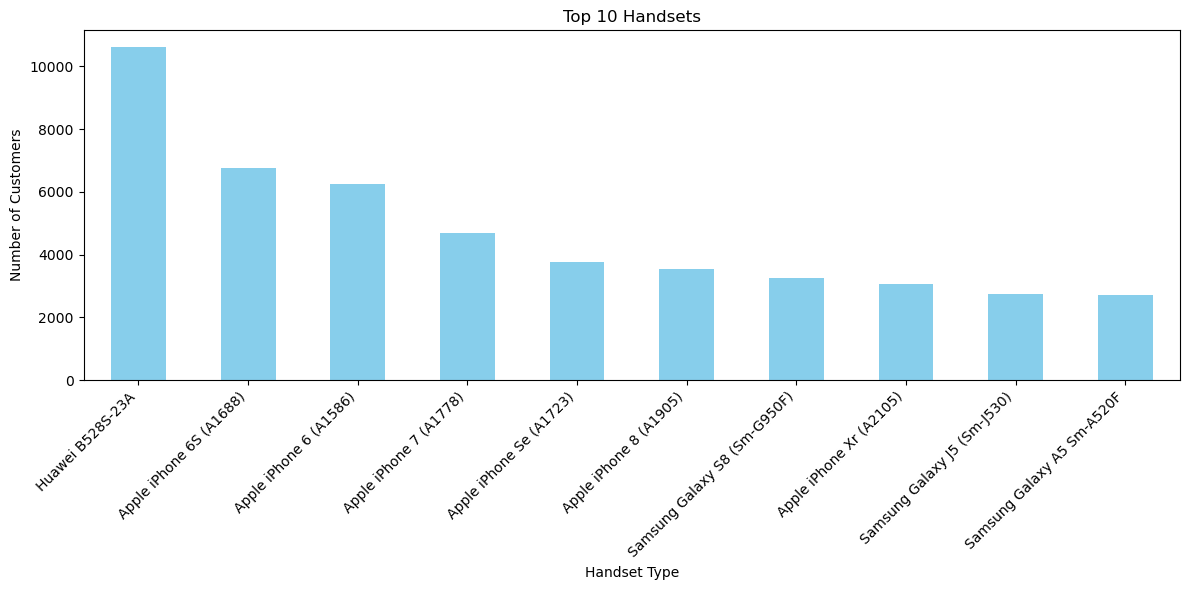


TOP 3 MANUFACTURERS
Handset Manufacturer
Apple      42592
Samsung    30780
Huawei     21692
Name: MSISDN/Number, dtype: int64


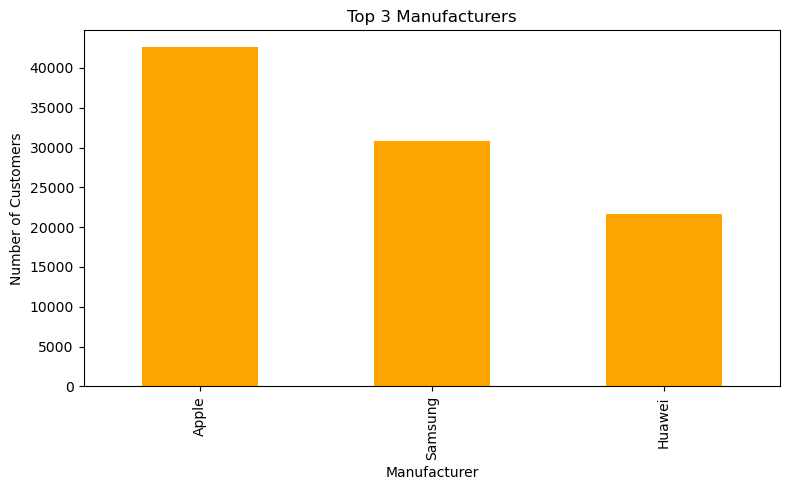


Manufacturer: Apple
Handset Type
Apple iPhone 6S (A1688)    6759
Apple iPhone 6 (A1586)     6260
Apple iPhone 7 (A1778)     4699
Apple iPhone Se (A1723)    3755
Apple iPhone 8 (A1905)     3543
Name: MSISDN/Number, dtype: int64


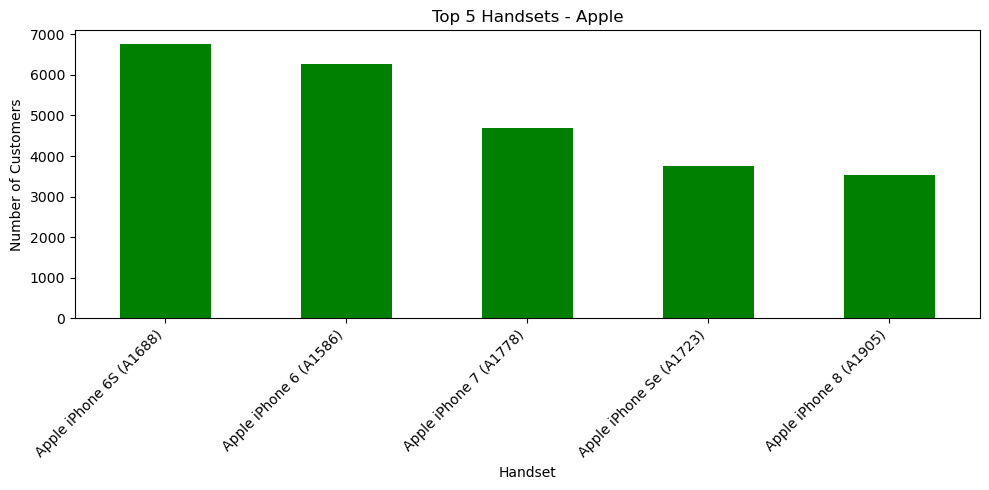


Manufacturer: Samsung
Handset Type
Samsung Galaxy S8 (Sm-G950F)    3245
Samsung Galaxy J5 (Sm-J530)     2748
Samsung Galaxy A5 Sm-A520F      2708
Samsung Galaxy J3 (Sm-J330)     2589
Samsung Galaxy S7 (Sm-G930X)    2292
Name: MSISDN/Number, dtype: int64


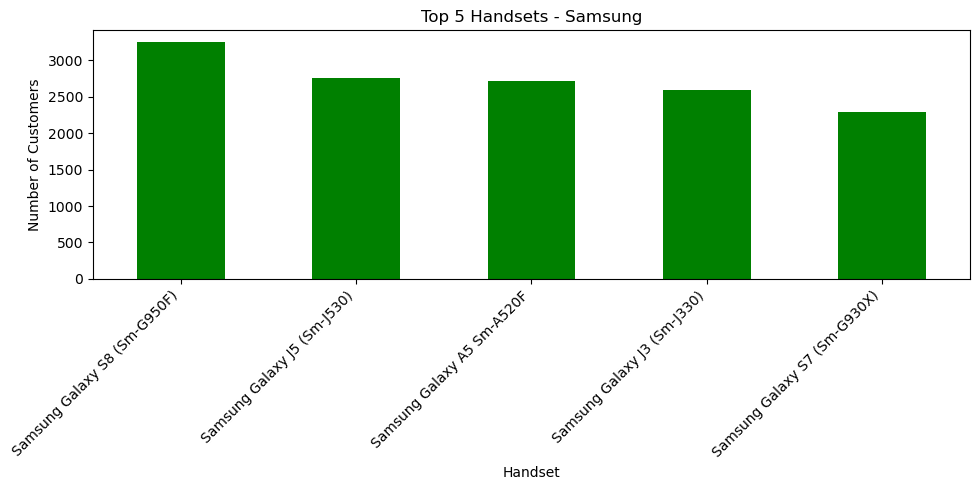


Manufacturer: Huawei
Handset Type
Huawei B528S-23A                  10616
Huawei P20 Lite Huawei Nova 3E     1531
Huawei E5180                       1182
Huawei P20                         1109
Huawei Y6 2018                      757
Name: MSISDN/Number, dtype: int64


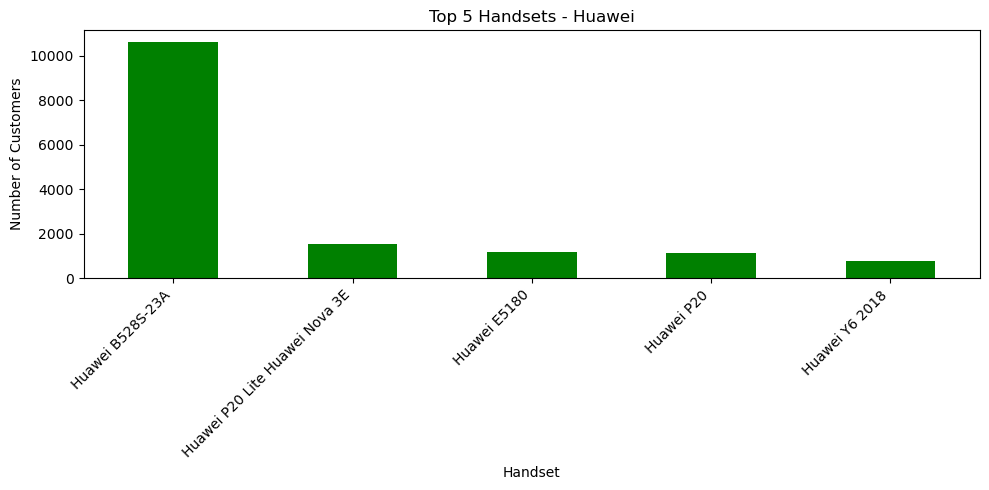

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Step 1: Load dataset
df = pd.read_excel(r"D:\NextHikes IT Solutions  project\User Analytics in the Telecommunication\telcom_data.xlsx")

# Step 2: Explore dataset
print("Shape:", df.shape)
print(df.head())
print(df.info())
print(df.columns.to_list)

# Step 3: Check missing values
print(df[['Handset Manufacturer',
          'Handset Type']].isnull().sum())

# Step 4: Clean handset columns
df['Handset Manufacturer'] = (
    df['Handset Manufacturer'].astype('string').str.strip()
)

df['Handset Type'] = (
    df['Handset Type'].astype('string').str.strip()
)

# Exclude missing and undefined handset models
clean_df = df[
    df['Handset Type'].notna() &
    df['Handset Type'].str.lower().ne('undefined')
].copy()

# Step 5: Top 10 handsets by unique customers
top10 = (
    clean_df.groupby('Handset Type')['MSISDN/Number']
    .nunique()
    .sort_values(ascending=False)
    .head(10)
)

print("\nTOP 10 HANDSETS")
print(top10)

# Visualization
plt.figure(figsize=(12, 6))
top10.plot(kind='bar', color='skyblue')
plt.title("Top 10 Handsets")
plt.xlabel("Handset Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Step 6: Top 3 manufacturers
valid_manufacturers = clean_df[
    clean_df['Handset Manufacturer'].notna() &
    clean_df['Handset Manufacturer'].str.lower().ne('undefined')
]

top3 = (
    valid_manufacturers.groupby('Handset Manufacturer')['MSISDN/Number']
    .nunique()
    .sort_values(ascending=False)
    .head(3)
)

print("\nTOP 3 MANUFACTURERS")
print(top3)

# Visualization
plt.figure(figsize=(8, 5))
top3.plot(kind='bar', color='orange')
plt.title("Top 3 Manufacturers")
plt.xlabel("Manufacturer")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

# Step 7: Top 5 handsets per manufacturer
for manufacturer in top3.index:

    manufacturer_data = valid_manufacturers[
        valid_manufacturers['Handset Manufacturer']
        == manufacturer
    ]

    top5 = (
        manufacturer_data.groupby('Handset Type')['MSISDN/Number']
        .nunique()
        .sort_values(ascending=False)
        .head(5)
    )

    print("\nManufacturer:", manufacturer)
    print(top5)

    plt.figure(figsize=(10, 5))
    top5.plot(kind='bar', color='green')
    plt.title(f"Top 5 Handsets - {manufacturer}")
    plt.xlabel("Handset")
    plt.ylabel("Number of Customers")
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()


In [2]:
#Python code – customer aggregation


import pandas as pd
import numpy as np

# Load dataset
df = pd.read_excel(r"D:\NextHikes IT Solutions  project\User Analytics in the Telecommunication\telcom_data.xlsx")

# Check duration columns
print([c for c in df.columns if 'Dur.' in c])

# Remove records without customer ID
df = df.dropna(subset=['MSISDN/Number'])

# Aggregate engagement metrics
user_engagement = df.groupby(
    'MSISDN/Number'
).agg(
    sessions=('Bearer Id', 'size'),
    duration_ms=('Dur. (ms)', 'sum'),
    total_dl_bytes=('Total DL (Bytes)', 'sum'),
    total_ul_bytes=('Total UL (Bytes)', 'sum')
).reset_index()

# Calculate total traffic
user_engagement['total_traffic_bytes'] = (
    user_engagement['total_dl_bytes'] +
    user_engagement['total_ul_bytes']
)

print(user_engagement.head())
print(user_engagement.shape)


['Dur. (ms)', 'Dur. (ms).1']
   MSISDN/Number  sessions  duration_ms  total_dl_bytes  total_ul_bytes  \
0   3.360100e+10         1     116720.0    8.426375e+08      36053108.0   
1   3.360100e+10         1     181230.0    1.207552e+08      36104459.0   
2   3.360100e+10         1     134969.0    5.566597e+08      39306820.0   
3   3.360101e+10         1      49878.0    4.019932e+08      20327526.0   
4   3.360101e+10         2      37104.0    1.363130e+09      94280527.0   

   total_traffic_bytes  
0         8.786906e+08  
1         1.568596e+08  
2         5.959665e+08  
3         4.223207e+08  
4         1.457411e+09  
(106856, 6)


In [3]:
# Top 10 customers by session frequency

top_sessions = user_engagement.sort_values(
    by='sessions',
    ascending=False
).head(10)

print(top_sessions[
    ['MSISDN/Number', 'sessions']
])

       MSISDN/Number  sessions
13526   3.362632e+10        18
13180   3.362578e+10        17
6437    3.361489e+10        17
37052   3.365973e+10        16
92923   3.376054e+10        15
76363   3.367588e+10        15
65118   3.366716e+10        13
13994   3.362708e+10        12
1279    3.360452e+10        12
92577   3.376041e+10        12


In [4]:
#Top 10 customers by session duration
top_duration = user_engagement.sort_values(
    by='duration_ms',
    ascending=False
).head(10)

print(top_duration[
    ['MSISDN/Number', 'duration_ms']
])

       MSISDN/Number  duration_ms
13180   3.362578e+10   18553754.0
6437    3.361489e+10    9966898.0
92923   3.376054e+10    9279434.0
13526   3.362632e+10    8791927.0
65118   3.366716e+10    8744914.0
50281   3.366284e+10    6614270.0
57160   3.366469e+10    6288730.0
666     3.360313e+10    6287761.0
66029   3.366746e+10    5649882.0
92577   3.376041e+10    5321667.0


In [5]:
# Top 10 customers by total traffic
top_traffic = user_engagement.sort_values(
    by='total_traffic_bytes',
    ascending=False
).head(10)

print(top_traffic[
    ['MSISDN/Number', 'total_traffic_bytes']
])

       MSISDN/Number  total_traffic_bytes
6437    3.361489e+10         8.846226e+09
92923   3.376054e+10         8.514774e+09
13180   3.362578e+10         8.499621e+09
13526   3.362632e+10         7.971167e+09
76363   3.367588e+10         7.891111e+09
37052   3.365973e+10         7.705863e+09
63028   3.366646e+10         7.308501e+09
92577   3.376041e+10         7.132371e+09
57241   3.366471e+10         6.872018e+09
86455   3.369879e+10         6.540899e+09


In [6]:
# Application-wise user engagement


applications = {
    'Social Media': [
        'Social Media DL (Bytes)',
        'Social Media UL (Bytes)'
    ],
    'Google': [
        'Google DL (Bytes)',
        'Google UL (Bytes)'
    ],
    'Email': [
        'Email DL (Bytes)',
        'Email UL (Bytes)'
    ],
    'Youtube': [
        'Youtube DL (Bytes)',
        'Youtube UL (Bytes)'
    ],
    'Netflix': [
        'Netflix DL (Bytes)',
        'Netflix UL (Bytes)'
    ],
    'Gaming': [
        'Gaming DL (Bytes)',
        'Gaming UL (Bytes)'
    ],
    'Other': [
        'Other DL (Bytes)',
        'Other UL (Bytes)'
    ]
}

# Calculate application traffic
for app, columns in applications.items():

    df[app + '_traffic'] = df[columns].sum(axis=1)

# Aggregate application traffic per customer
app_engagement = df.groupby(
    'MSISDN/Number'
)[[app + '_traffic' for app in applications]].sum()

# Top 10 customers per application
for app in applications:

    column = app + '_traffic'

    print("\nTop 10 customers:", app)

    print(
        app_engagement[column]
        .nlargest(10)
    )

# Total traffic per application
app_totals = app_engagement.sum()

print("\nTotal application traffic")
print(app_totals.sort_values(ascending=False))



Top 10 customers: Social Media
MSISDN/Number
3.362632e+10    43374779.0
3.376054e+10    39783189.0
3.365973e+10    35412358.0
3.361489e+10    28294544.0
3.362578e+10    27135500.0
3.366716e+10    24247850.0
3.378632e+10    23974919.0
3.366907e+10    23800834.0
3.360313e+10    23077825.0
3.365849e+10    23000066.0
Name: Social Media_traffic, dtype: float64

Top 10 customers: Google
MSISDN/Number
3.362632e+10    152191852.0
3.362578e+10    142307915.0
3.361489e+10    127973787.0
3.376054e+10    123223099.0
3.365973e+10    116516345.0
3.378632e+10    110254484.0
3.367588e+10    109860502.0
3.366716e+10    105032696.0
3.376127e+10     97089988.0
3.369876e+10     91935151.0
Name: Google_traffic, dtype: float64

Top 10 customers: Email
MSISDN/Number
3.362632e+10    42418782.0
3.361489e+10    40788634.0
3.362578e+10    40633966.0
3.378632e+10    36310123.0
3.365973e+10    35999792.0
3.376054e+10    33693767.0
3.367588e+10    31514421.0
3.366546e+10    30417885.0
3.366716e+10    30335796.0
3.

In [7]:
# Normalize the engagement metrics and apply K-means clustering

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Select engagement features
features = [
    'sessions',
    'duration_ms',
    'total_traffic_bytes'
]

# Normalize data
scaler = StandardScaler()

normalized_data = scaler.fit_transform(
    user_engagement[features]
)

# Apply K-means with k=3
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

user_engagement['cluster'] = kmeans.fit_predict(
    normalized_data
)

print(user_engagement['cluster'].value_counts())


cluster
0    79850
2    23459
1     3547
Name: count, dtype: int64


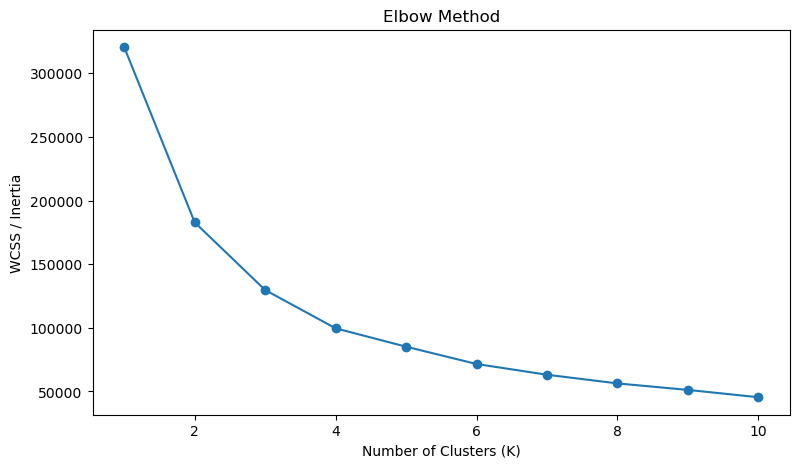

In [8]:
# Find the optimized K using the Elbow Method

import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

wcss = []

for k in range(1, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(normalized_data)

    wcss.append(model.inertia_)

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, 11),
    wcss,
    marker='o'
)

plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS / Inertia")

plt.show()

wel come python
Dataset shape: (150001, 55)


,Bearer Id,Start,Start ms,End,End ms,Dur. (ms),IMSI,MSISDN/Number,IMEI,Last Location Name,...,Youtube DL (Bytes),Youtube UL (Bytes),Netflix DL (Bytes),Netflix UL (Bytes),Gaming DL (Bytes),Gaming UL (Bytes),Other DL (Bytes),Other UL (Bytes),Total UL (Bytes),Total DL (Bytes)
0,13114483460844900352,2019-04-04 12:01:18,770.0,2019-04-25 14:35:31,662.0,1823652.0,2.082014e+14,3.366496e+10,3.552121e+13,9164566995485190,...,15854611.0,2501332.0,8198936.0,9656251.0,278082303.0,14344150.0,171744450.0,8814393.0,36749741.0,308879636.0
1,13114483482878900224,2019-04-09 13:04:04,235.0,2019-04-25 08:15:48,606.0,1365104.0,2.082019e+14,3.368185e+10,3.579401e+13,L77566A,...,20247395.0,19111729.0,18338413.0,17227132.0,608750074.0,1170709.0,526904238.0,15055145.0,53800391.0,653384965.0
2,13114483484080500736,2019-04-09 17:42:11,1.0,2019-04-25 11:58:13,652.0,1361762.0,2.082003e+14,3.376063e+10,3.528151e+13,D42335A,...,19725661.0,14699576.0,17587794.0,6163408.0,229584621.0,395630.0,410692588.0,4215763.0,27883638.0,279807335.0
3,13114483485442799616,2019-04-10 00:31:25,486.0,2019-04-25 07:36:35,171.0,1321509.0,2.082014e+14,3.375034e+10,3.535661e+13,T21824A,...,21388122.0,15146643.0,13994646.0,1097942.0,799538153.0,10849722.0,749039933.0,12797283.0,43324218.0,846028530.0
4,13114483499480700928,2019-04-12 20:10:23,565.0,2019-04-25 10:40:32,954.0,1089009.0,2.082014e+14,3.369980e+10,3.540701e+13,D88865A,...,15259380.0,18962873.0,17124581.0,415218.0,527707248.0,3529801.0,550709500.0,13910322.0,38542814.0,569138589.0


<bound method IndexOpsMixin.tolist of Index(['Bearer Id', 'Start', 'Start ms', 'End', 'End ms', 'Dur. (ms)', 'IMSI',
       'MSISDN/Number', 'IMEI', 'Last Location Name', 'Avg RTT DL (ms)',
       'Avg RTT UL (ms)', 'Avg Bearer TP DL (kbps)', 'Avg Bearer TP UL (kbps)',
       'TCP DL Retrans. Vol (Bytes)', 'TCP UL Retrans. Vol (Bytes)',
       'DL TP < 50 Kbps (%)', '50 Kbps < DL TP < 250 Kbps (%)',
       '250 Kbps < DL TP < 1 Mbps (%)', 'DL TP > 1 Mbps (%)',
       'UL TP < 10 Kbps (%)', '10 Kbps < UL TP < 50 Kbps (%)',
       '50 Kbps < UL TP < 300 Kbps (%)', 'UL TP > 300 Kbps (%)',
       'HTTP DL (Bytes)', 'HTTP UL (Bytes)', 'Activity Duration DL (ms)',
       'Activity Duration UL (ms)', 'Dur. (ms).1', 'Handset Manufacturer',
       'Handset Type', 'Nb of sec with 125000B < Vol DL',
       'Nb of sec with 1250B < Vol UL < 6250B',
       'Nb of sec with 31250B < Vol DL < 125000B',
       'Nb of sec with 37500B < Vol UL',
       'Nb of sec with 6250B < Vol DL < 31250B',
       'Nb 

,MSISDN/Number,TCP Retransmission,RTT,Throughput,Handset Type
0,3.360100e+10,1.078479e+07,23.000000,38.000000,Huawei P20 Lite Huawei Nova 3E
1,3.360100e+10,1.078479e+07,15.500000,49.500000,Apple iPhone 7 (A1778)
2,3.360100e+10,1.078479e+07,63.729294,48.500000,undefined
3,3.360101e+10,3.803623e+05,42.000000,124.000000,Apple iPhone 5S (A1457)
4,3.360101e+10,7.735101e+06,29.750000,10551.357162,Apple iPhone Se (A1723)


Customer experience shape: (106856, 5)

========== TCP Retransmission ==========

Top 10:


,MSISDN/Number,TCP Retransmission
72750,3.366969e+10,2.530242e+07
37013,3.365971e+10,2.515900e+07
26714,3.365088e+10,2.512970e+07
43785,3.366135e+10,2.508386e+07
31898,3.365863e+10,2.506801e+07
27234,3.365099e+10,2.506671e+07
72271,3.366951e+10,2.504390e+07
54920,3.366403e+10,2.501955e+07
56192,3.366441e+10,2.500203e+07
32676,3.365878e+10,2.492142e+07


... (12 outputs left out)


Bottom 10:


,MSISDN/Number,Throughput
857,3.360345e+10,0.0
1204,3.360413e+10,0.0
2473,3.360851e+10,0.0
2605,3.360875e+10,0.0
2671,3.360889e+10,0.0
3238,3.360985e+10,0.0
3738,3.361064e+10,0.0
4276,3.361152e+10,0.0
7196,3.361611e+10,0.0
7518,3.361661e+10,0.0



Most Frequent 10:


Throughput
7535.237287    3167
7.500000       2872
31.500000      2138
48.500000      1094
45.000000      1062
49.000000      1025
48.000000       938
49.500000       918
44.500000       881
45.500000       864
Name: count, dtype: int64

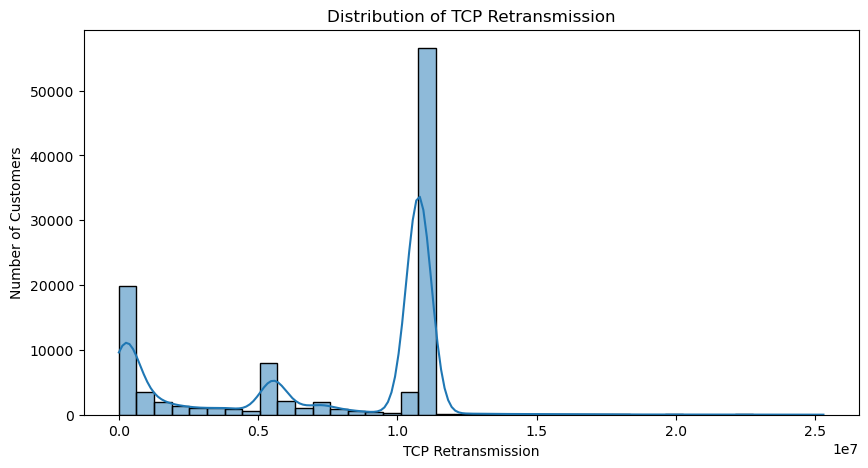

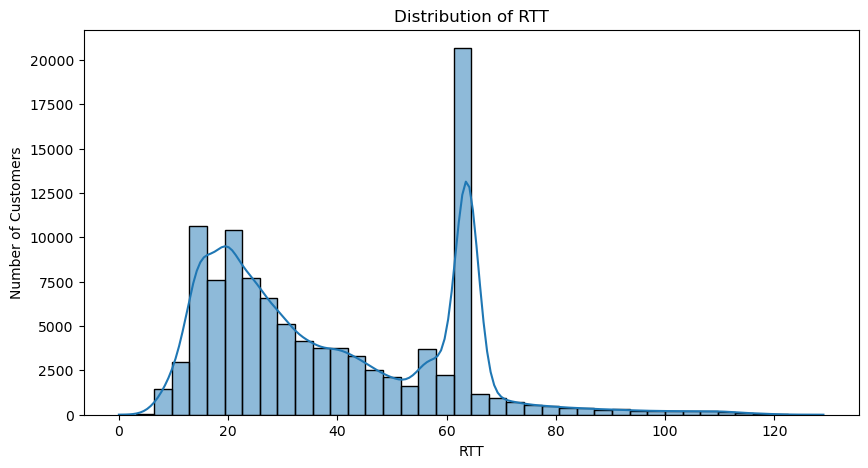

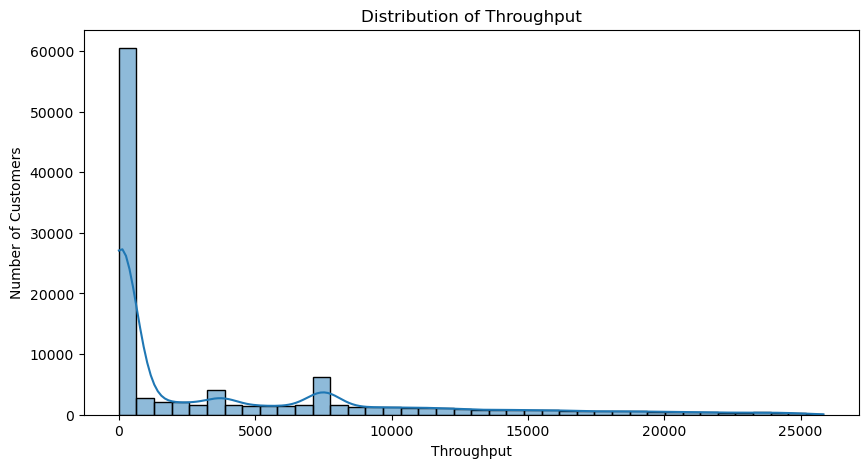

,TCP Retransmission,RTT,Throughput
Handset Type,,,
Xiaomi Communica. M1803E1A,5.485350e+04,22.5,25471.214323
Xiaomi Communica. Redmi Note 2,1.096244e+06,18.5,24690.500000
Huawei Nova 2I Huawei Mate 10 Lite,4.738578e+05,12.5,23830.500000
Htc 2Q6E100,1.447000e+03,21.5,23746.500000
Lephone U Pro,4.311505e+05,14.5,22834.500000
Huawei Stf-Tl10,6.699200e+04,17.5,22628.500000
Huawei Vns-Dl00,3.957893e+05,20.5,22571.500000
Xiaomi Communica. B5,1.002210e+07,37.0,22183.000000
Samsung Galaxy S9 Sm-G960N,4.762423e+05,31.0,22177.500000


In [9]:
# Experience Analytics

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

print("wel come python")
df=pd.read_excel(r"D:\NextHikes IT Solutions  project\User Analytics in the Telecommunication\telcom_data.xlsx")
print("Dataset shape:", df.shape)
display(df.head())
print(df.columns.tolist)

# Handle missing values
numeric_columns = [
    'TCP DL Retrans. Vol (Bytes)',
    'TCP UL Retrans. Vol (Bytes)',
    'Avg RTT DL (ms)',
    'Avg RTT UL (ms)',
    'Avg Bearer TP DL (kbps)',
    'Avg Bearer TP UL (kbps)'
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')
    df[col] = df[col].fillna(df[col].mean())

df['Handset Type'] = df['Handset Type'].fillna(
    df['Handset Type'].mode()[0]
)

print(df.isnull().sum())

# Handle outliers using IQR

for col in numeric_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    mean_value = df[col].mean()

    df.loc[
        (df[col] < lower) | (df[col] > upper), col
    ] = mean_value

# Aggregate metrics per customer.

df['TCP Retransmission'] = (
    df['TCP DL Retrans. Vol (Bytes)'] +
    df['TCP UL Retrans. Vol (Bytes)']
) / 2

df['RTT'] = (
    df['Avg RTT DL (ms)'] +
    df['Avg RTT UL (ms)']
) / 2

df['Throughput'] = (
    df['Avg Bearer TP DL (kbps)'] +
    df['Avg Bearer TP UL (kbps)']
) / 2

experience = df.groupby('MSISDN/Number').agg({

    'TCP Retransmission': 'mean',
    'RTT': 'mean',
    'Throughput': 'mean',
    'Handset Type': lambda x: x.mode().iloc[0]

}).reset_index()

display(experience.head())

print("Customer experience shape:", experience.shape)

# Find top 10, bottom 10 and most frequent values

metrics = [
    'TCP Retransmission',
    'RTT',
    'Throughput'
]

for col in metrics:

    print("\n==========", col, "==========")

    print("\nTop 10:")
    display(experience.nlargest(10, col)[['MSISDN/Number', col]])

    print("\nBottom 10:")
    display(experience.nsmallest(10, col)[['MSISDN/Number', col]])

    print("\nMost Frequent 10:")
    display(experience[col].value_counts().head(10))

#  Visualize network experience

for col in metrics:

    plt.figure(figsize=(10, 5))

    sns.histplot(experience[col], bins=40, kde=True)

    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Number of Customers')

    plt.show()

# Analyze handset experience

handset_experience = experience.groupby(
    'Handset Type'
).agg({
    'TCP Retransmission': 'mean',
    'RTT': 'mean',
    'Throughput': 'mean'
}).sort_values(
    'Throughput', ascending=False
)

display(handset_experience.head(10))


In [ ]:
#  User Satisfaction Analysis

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

final_df = pd.merge(
    user_engagement,
    experience,
    on='MSISDN/Number',
    how='inner'
)

display(final_df.head())

# Calculate Satisfaction Score

final_df['Satisfaction Score'] = (
    final_df['Engagement Score'] +
    final_df['Experience Score']
) / 2

top_10 = final_df.nlargest(
    10, 'Satisfaction Score'
)

display(top_10[
    ['MSISDN/Number',
     'Engagement Score',
     'Experience Score',
     'Satisfaction Score']
])

#  K-Means clustering (K=2)

features = final_df[
    ['Engagement Score', 'Experience Score']
]

scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

final_df['Satisfaction Cluster'] = (
    kmeans.fit_predict(scaled_features)
)

# Cluster analysis

cluster_summary = final_df.groupby(
    'Satisfaction Cluster'
).agg({
    'Satisfaction Score': 'mean',
    'Experience Score': 'mean',
    'Engagement Score': 'mean'
})

display(cluster_summary)

# Export final results
final_df[[
    'MSISDN/Number',
    'Engagement Score',
    'Experience Score',
    'Satisfaction Score'
]].to_csv(
    'telecom_customer_satisfaction.csv',
    index=False
)

